In [ ]:
!pip install yfinance pandas numpy scipy tabulate

In [ ]:
!pip install yfinance pandas numpy scipy tabulate

In [ ]:
!pip install yfinance pandas numpy scipy tabulate arch statsmodels seaborn pandas-datareader


********************************************************************************
  SISTEMA INTEGRAL DE ANÁLISIS CUANTITATIVO
********************************************************************************
1. Análisis Fundamental de Acción Completo (Tablas & Resumen)
2. Evaluación de Riesgo/Retorno y Monte Carlo Comparativo (CSV)
3. Motor de Machine Learning (Predicción a 2 Meses)
4. Análisis Institucional: Matriz, GARCH y Fama-French (CSV)
********************************************************************************

Elige el número de la herramienta que deseas usar (1, 2, 3 o 4): 4

Por favor, sube tu archivo CSV de portafolio para el análisis avanzado:


Saving CSV de mi portafolio.txt to CSV de mi portafolio (9).txt

  ANÁLISIS INSTITUCIONAL: MATRIZ DE RIESGO, GARCH Y FAMA-FRENCH
📡 Descargando datos del portafolio...

📊 1. ANÁLISIS DE CORRELACIÓN Y EFICIENCIA DE DIVERSIFICACIÓN
| Métrica de Concentración                      | Resultado   |
|-----------------------------------------------|-------------|
| Índice de Correlación Estructural             | 32.29%      |
| Volatilidad Bruta de Activos (Riesgo Aislado) | 44.01%      |
| Volatilidad Real del Portafolio               | 29.34%      |
| Riesgo Eliminado por Diversificación          | 33.34%      |
🟢 SALUDABLE: Tu selección de activos está logrando cancelar efectivamente el riesgo mediante una correlación equilibrada.


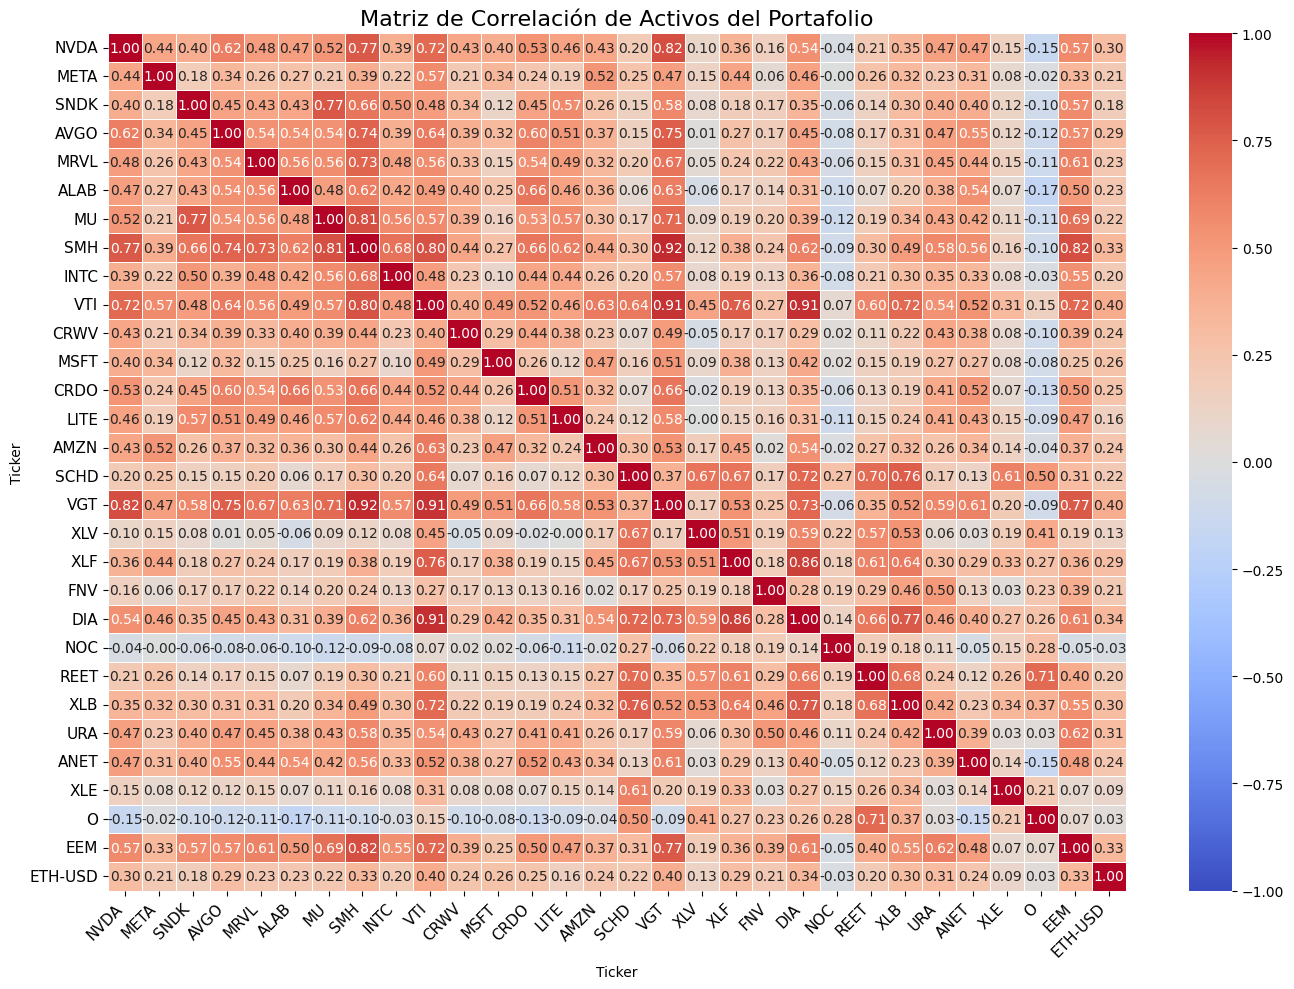


📈 2. MODELO GARCH(1,1): PREDICCIÓN DE VOLATILIDAD CONDICIONAL
El modelo GARCH ajusta el VaR asumiendo que la volatilidad se agrupa en 'tormentas' (clusters).
| Horizonte Inmediato   | Volatilidad GARCH Proyectada     |
|-----------------------|----------------------------------|
| Día 1                 | 6.12% diaria (97.22% anualizada) |
| Día 2                 | 6.13% diaria (97.27% anualizada) |
| Día 3                 | 6.13% diaria (97.32% anualizada) |
| Día 4                 | 6.13% diaria (97.37% anualizada) |
| Día 5                 | 6.14% diaria (97.42% anualizada) |

🔬 3. REGRESIÓN DE FAMA-FRENCH (Atribución de Rendimiento)
Audita de dónde proviene tu retorno: Mercado (MKT), Tamaño (SMB), o Valor (HML).
| Factor                                   | Coeficiente                    |
|------------------------------------------|--------------------------------|
| Alpha Diario (Habilidad del Gestor)      | 0.2081%                        |
| Beta MKT (Exposición al Mercado)      

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
from scipy.stats import norm
import io
import requests
from google.colab import files
from tabulate import tabulate
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import pandas_datareader.data as web
from arch import arch_model
warnings.filterwarnings('ignore')

# ==========================================
# 2. VARIABLES GLOBALES DE CONFIGURACIÓN
# ==========================================
RISK_FREE_RATE = 0.042
BENCHMARK_TICKER = "^GSPC"
YEARS_HISTOGRAM = 2

# ==========================================
# MÓDULO 1: ANÁLISIS FUNDAMENTAL (COMPLETO)
# ==========================================
def analizar_accion(ticker_symbol):
    print(f"\n" + "="*80)
    print(f"  REPORTE DE ANÁLISIS FUNDAMENTAL COMPLETO: {ticker_symbol.upper()}")
    print("  Fuente de datos: Yahoo Finance (Datos Oficiales y Consenso de Analistas)")
    print("="*80)

    stock = yf.Ticker(ticker_symbol)
    info = stock.info

    if not info or 'shortName' not in info:
        print(f"❌ No se pudo encontrar información para el ticker: {ticker_symbol}")
        return

    # --- SECCIÓN 1: RESUMEN Y MÉTRICAS CLAVE ---
    print("\n--- RESUMEN GENERAL ---")
    resumen_data = [
        ["Nombre:", info.get("shortName", "N/A")],
        ["Sector / Industria:", f"{info.get('sector', 'N/A')} / {info.get('industry', 'N/A')}"],
        ["Precio Actual:", f"${info.get('currentPrice', info.get('regularMarketPrice', 0)):,.2f}"],
        ["Market Cap:", f"${info.get('marketCap', 0):,}"],
        ["Target Price (Consenso):", f"${info.get('targetMeanPrice', 0):,.2f}"],
        ["Beta (Riesgo vs Mercado):", info.get("beta", "N/A")]
    ]
    print(tabulate(resumen_data, tablefmt="plain"))

    # --- SECCIÓN 2: VALUACIÓN, CRECIMIENTO Y MÁRGENES ---
    print("\n--- MÉTRICAS FUNDAMENTALES (TTM / F1) ---")
    fund_data = [
        ["P/E (TTM)", info.get("trailingPE", "NA"), "Margen Bruto", f"{info.get('grossMargins', 0)*100:.2f}%" if info.get('grossMargins') else "NA"],
        ["Forward P/E (F1)", info.get("forwardPE", "NA"), "Margen Operativo", f"{info.get('operatingMargins', 0)*100:.2f}%" if info.get('operatingMargins') else "NA"],
        ["PEG Ratio", info.get("pegRatio", "NA"), "Margen Neto", f"{info.get('profitMargins', 0)*100:.2f}%" if info.get('profitMargins') else "NA"],
        ["Price to Book (P/B)", info.get("priceToBook", "NA"), "Crec. Ingresos (YoY)", f"{info.get('revenueGrowth', 0)*100:.2f}%" if info.get('revenueGrowth') else "NA"],
        ["EV/EBITDA", info.get("enterpriseToEbitda", "NA"), "Crec. EPS (YoY)", f"{info.get('earningsGrowth', 0)*100:.2f}%" if info.get('earningsGrowth') else "NA"],
        ["Current Ratio", info.get("currentRatio", "NA"), "Debt to Equity", info.get("debtToEquity", "NA")]
    ]
    print(tabulate(fund_data, headers=["Valuación", "Valor", "Rentabilidad / Salud", "Valor"], tablefmt="simple"))

    # --- SECCIÓN 3: MÉTRICAS TRIMESTRALES HISTÓRICAS ---
    print("\n--- HISTORIAL TRIMESTRAL (ÚLTIMOS 3 TRIMESTRES) ---")
    try:
        bs = stock.quarterly_balance_sheet
        fin = stock.quarterly_financials
        fechas = bs.columns[:3] if len(bs.columns) >= 3 else bs.columns

        combined_q_data = []

        for fecha in fechas:
            fecha_str = fecha.strftime('%m/%d/%y')

            # Cálculos trimestrales seguros
            net_income = fin.loc['Net Income', fecha] if 'Net Income' in fin.index else np.nan
            total_equity = bs.loc['Stockholders Equity', fecha] if 'Stockholders Equity' in bs.index else np.nan
            total_assets = bs.loc['Total Assets', fecha] if 'Total Assets' in bs.index else np.nan
            current_assets = bs.loc['Current Assets', fecha] if 'Current Assets' in bs.index else np.nan
            current_liab = bs.loc['Current Liabilities', fecha] if 'Current Liabilities' in bs.index else np.nan
            operating_income = fin.loc['Operating Income', fecha] if 'Operating Income' in fin.index else np.nan
            total_revenue = fin.loc['Total Revenue', fecha] if 'Total Revenue' in fin.index else np.nan

            # Ratios
            roe = (net_income / total_equity) * 100 if pd.notna(net_income) and pd.notna(total_equity) and total_equity != 0 else "NA"
            roa = (net_income / total_assets) * 100 if pd.notna(net_income) and pd.notna(total_assets) and total_assets != 0 else "NA"
            cr = current_assets / current_liab if pd.notna(current_assets) and pd.notna(current_liab) and current_liab != 0 else "NA"
            op_margin = (operating_income / total_revenue) * 100 if pd.notna(operating_income) and pd.notna(total_revenue) and total_revenue != 0 else "NA"

            combined_q_data.append([
                fecha_str,
                f"{roe:.2f}%" if isinstance(roe, float) else roe,
                f"{roa:.2f}%" if isinstance(roa, float) else roa,
                f"{cr:.2f}" if isinstance(cr, float) else cr,
                f"{op_margin:.2f}%" if isinstance(op_margin, float) else op_margin
            ])

        print(tabulate(combined_q_data, headers=["Fecha", "ROE", "ROA", "Current Ratio", "Margen Oper."], tablefmt="github"))

    except Exception as e:
        print("\n⚠️ Datos trimestrales históricos no disponibles o incompletos en la base de datos de Yahoo Finance para estructurar la tabla.")


# ==========================================
# MÓDULO 2: EVALUACIÓN DE PORTAFOLIO Y MONTE CARLO DUAL (VERSIÓN COMPLETA)
# ==========================================
def analizar_portafolio_df(df_portfolio):
    print(f"\n" + "="*80)
    print("  EVALUACIÓN DE RIESGO, RETORNO Y PRUEBA DE ESTRÉS (VS S&P 500)")
    print("="*80)

    # 1. Solicitar el valor real del portafolio
    while True:
        try:
            inversion_inicial = float(input("\n💰 Ingresa el valor total actual de tu portafolio en USD (ej. 12500.50): "))
            break
        except ValueError:
            print("❌ Por favor ingresa un número válido sin símbolos de moneda.")

    df_portfolio.columns = [c.lower().strip() for c in df_portfolio.columns]
    if 'ticker' not in df_portfolio.columns or 'weight' not in df_portfolio.columns:
        print("❌ El CSV debe contener las columnas 'ticker' y 'weight'.")
        return

    # Ajustar formato de criptomonedas comunes si es necesario
    df_portfolio['ticker'] = df_portfolio['ticker'].str.upper().str.replace('ETHUSD', 'ETH-USD').str.replace('BTCUSD', 'BTC-USD')

    tickers = df_portfolio['ticker'].tolist()
    weights_dict = dict(zip(tickers, pd.to_numeric(df_portfolio['weight'], errors='coerce')))

    all_tickers = tickers + [BENCHMARK_TICKER]
    data = yf.download(all_tickers, period=f"{YEARS_HISTOGRAM}y", progress=False)['Close']
    data = data.ffill()

    # Validar qué activos realmente tienen datos
    available_tickers = [t for t in tickers if t in data.columns and not data[t].dropna().empty]
    failed_tickers = [t for t in tickers if t not in available_tickers]

    if failed_tickers:
        print(f"⚠️ Advertencia: No se encontraron datos históricos para: {failed_tickers}. Se omitirán del análisis.")

    if not available_tickers:
        print("❌ Error: No hay datos disponibles para ninguno de los activos ingresados.")
        return

    # Recalcular pesos para los activos disponibles
    valid_weights = np.array([weights_dict[t] for t in available_tickers], dtype=float)
    valid_weights = valid_weights / np.sum(valid_weights)

    returns = data[available_tickers + [BENCHMARK_TICKER]].pct_change().dropna()

    portfolio_returns = (returns[available_tickers] * valid_weights).sum(axis=1)
    benchmark_returns = returns[BENCHMARK_TICKER]

    # --- 2. CÁLCULO DE MÉTRICAS CLÁSICAS ---
    retorno_diario_prom_port = portfolio_returns.mean()
    vol_diaria_port = portfolio_returns.std()
    retorno_diario_prom_sp = benchmark_returns.mean()
    vol_diaria_sp = benchmark_returns.std()

    cumulative_returns = (1 + returns).cumprod()
    portfolio_cumulative = (cumulative_returns[available_tickers] * valid_weights).sum(axis=1)

    vol_anualizada = vol_diaria_port * np.sqrt(252)
    dias_totales = len(portfolio_cumulative)
    retorno_anualizado = (portfolio_cumulative.iloc[-1] / portfolio_cumulative.iloc[0])**(252 / dias_totales) - 1 if dias_totales > 0 and portfolio_cumulative.iloc[0] > 0 else 0

    sharpe_ratio = (retorno_anualizado - RISK_FREE_RATE) / vol_anualizada if vol_anualizada != 0 else np.nan
    downside_std_anual = portfolio_returns[portfolio_returns < 0].std() * np.sqrt(252)
    sortino_ratio = (retorno_anualizado - RISK_FREE_RATE) / downside_std_anual if downside_std_anual != 0 else np.nan

    beta = np.cov(portfolio_returns, benchmark_returns)[0][1] / np.var(benchmark_returns) if np.var(benchmark_returns) != 0 else np.nan
    treynor_ratio = (retorno_anualizado - RISK_FREE_RATE) / beta if beta != 0 else np.nan

    var_95_historico = np.percentile(portfolio_returns, 5) if len(portfolio_returns) > 0 else np.nan
    cvar_95 = portfolio_returns[portfolio_returns <= var_95_historico].mean() if len(portfolio_returns) > 0 else np.nan

    cumulative_returns_port = (1 + portfolio_returns).cumprod()
    peak = cumulative_returns_port.cummax()
    max_drawdown = ((cumulative_returns_port - peak) / peak).min() if len(cumulative_returns_port) > 0 else np.nan
    calmar_ratio = retorno_anualizado / abs(max_drawdown) if max_drawdown != 0 else np.nan

    print("\n--- MÉTRICAS HISTÓRICAS DEL PORTAFOLIO ---")
    resultados = [
        ("Rendimiento Anualizado Estimado (CAGR)", f"{retorno_anualizado*100:.2f}%" if pd.notna(retorno_anualizado) else "NA"),
        ("Volatilidad Anualizada", f"{vol_anualizada*100:.2f}%" if pd.notna(vol_anualizada) else "NA"),
        ("Ratio de Sharpe", f"{sharpe_ratio:.2f}" if pd.notna(sharpe_ratio) else "NA"),
        ("Ratio de Sortino", f"{sortino_ratio:.2f}" if pd.notna(sortino_ratio) else "NA"),
        ("Beta (vs. S&P 500)", f"{beta:.2f}" if pd.notna(beta) else "NA"),
        ("Ratio de Treynor", f"{treynor_ratio:.2f}" if pd.notna(treynor_ratio) else "NA"),
        ("Maximum Drawdown (Caída Máx. Histórica)", f"{max_drawdown*100:.2f}%" if pd.notna(max_drawdown) else "NA"),
        ("Ratio de Calmar", f"{calmar_ratio:.2f}" if pd.notna(calmar_ratio) else "NA"),
        ("VaR Diario (Histórico 95%)", f"{var_95_historico*100:.2f}%" if pd.notna(var_95_historico) else "NA"),
        ("CVaR / Expected Shortfall (95%)", f"{cvar_95*100:.2f}%" if pd.notna(cvar_95) else "NA")
    ]
    print(tabulate(resultados, headers=["Métrica de Riesgo / Retorno", "Valor"], tablefmt="github"))

    # --- 3. SIMULACIÓN DE MONTE CARLO DUAL (BOOTSTRAPPING) ---
    print("\n" + "="*80)
    print("  SIMULACIÓN DE MONTE CARLO: PROYECCIÓN A 1 AÑO (BOOTSTRAPPING HISTÓRICO)")
    print("="*80)

    num_simulations = 10000
    time_horizon = 252 # 1 Año de días hábiles

    hist_ret_port = portfolio_returns.values
    hist_ret_sp = benchmark_returns.values

    # Simulaciones (Muestreo con reemplazo para incluir colas pesadas)
    sim_ret_port = np.random.choice(hist_ret_port, size=(time_horizon, num_simulations), replace=True)
    sim_paths_port = np.cumprod(1 + sim_ret_port, axis=0) * inversion_inicial
    final_values_port = sim_paths_port[-1, :]

    sim_ret_sp = np.random.choice(hist_ret_sp, size=(time_horizon, num_simulations), replace=True)
    sim_paths_sp = np.cumprod(1 + sim_ret_sp, axis=0) * inversion_inicial
    final_values_sp = sim_paths_sp[-1, :]

    # Cálculos estadísticos (Campana de Gauss simulada)
    media_port = np.mean(final_values_port)
    std_port = np.std(final_values_port)
    extremo_2sd_port = media_port - (2 * std_port)
    caida_pct_port = (extremo_2sd_port / inversion_inicial) - 1

    media_sp = np.mean(final_values_sp)
    std_sp = np.std(final_values_sp)
    extremo_2sd_sp = media_sp - (2 * std_sp)
    caida_pct_sp = (extremo_2sd_sp / inversion_inicial) - 1

    diferencial_riesgo = caida_pct_port - caida_pct_sp

    mc_results = [
        ("Inversión Actual Base", f"${inversion_inicial:,.2f}", f"${inversion_inicial:,.2f}"),
        ("Valor Esperado Promedio (Media μ)", f"${media_port:,.2f}", f"${media_sp:,.2f}"),
        ("Desviación Estándar Anual (σ)", f"± ${std_port:,.2f}", f"± ${std_sp:,.2f}"),
        ("Escenario de Crisis Severa (-2σ)", f"${extremo_2sd_port:,.2f}", f"${extremo_2sd_sp:,.2f}"),
        ("Pérdida de Capital en Crisis (-2σ)", f"{caida_pct_port*100:.2f}%", f"{caida_pct_sp*100:.2f}%")
    ]
    print(tabulate(mc_results, headers=["Métrica a 1 Año (10,000 Iteraciones)", "Tu Portafolio", "S&P 500 (Benchmark)"], tablefmt="github"))

    # --- 4. SISTEMA DE ALERTA (COMPLIANCE IPS) ---
    print("\n" + "="*80)
    print("  AUDITORÍA DE RIESGO RELATIVO (Tracking Error vs IPS)")
    print("="*80)
    print(f"Diferencial de caída en escenario severo (-2σ): {diferencial_riesgo*100:.2f}% frente al mercado.")

    if diferencial_riesgo < -0.02:
        print("🔴 ALERTA DE POLÍTICA: Tu portafolio proyecta una caída que supera el margen de riesgo del 2% sobre el índice.")
        print("   Acción Requerida: Reestructurar posiciones reduciendo activos de alta Beta para cumplir el IPS.")
    else:
        print("🟢 APROBADO: El portafolio se mantiene dentro de los límites de riesgo relativo tolerados frente al mercado.")

    # --- 5. GRÁFICOS COMBINADOS ---
    try:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

        # Gráfico 1: Trayectorias del Portafolio (Muestra de 100)
        ax1.plot(sim_paths_port[:, :100], color='royalblue', alpha=0.1)
        ax1.axhline(inversion_inicial, color='black', linestyle='--', label="Capital Inicial")
        ax1.axhline(media_port, color='green', linestyle='-', label=f"Media: ${media_port:,.0f}")
        ax1.axhline(extremo_2sd_port, color='red', linestyle='-', label=f"Crisis -2σ: ${extremo_2sd_port:,.0f}")
        ax1.set_title("Trayectorias Monte Carlo (Tu Portafolio)")
        ax1.set_xlabel("Días Hábiles (1 Año = 252 días)")
        ax1.set_ylabel("Valor Proyectado ($)")
        ax1.legend(loc="upper left")
        ax1.grid(True, alpha=0.3)

        # Gráfico 2: Histograma Comparativo (Campana de Gauss)
        ax2.hist(final_values_port, bins=50, density=True, alpha=0.5, color='royalblue', label='Tu Portafolio')
        x_port = np.linspace(min(final_values_port), max(final_values_port), 100)
        ax2.plot(x_port, norm.pdf(x_port, media_port, std_port), color='darkblue', linewidth=2)

        ax2.hist(final_values_sp, bins=50, density=True, alpha=0.4, color='gray', label='S&P 500')
        x_sp = np.linspace(min(final_values_sp), max(final_values_sp), 100)
        ax2.plot(x_sp, norm.pdf(x_sp, media_sp, std_sp), color='black', linewidth=2, linestyle='--')

        ax2.axvline(extremo_2sd_port, color='red', linestyle='--', linewidth=2, label=f'-2σ Portafolio')
        ax2.axvline(extremo_2sd_sp, color='darkred', linestyle='-.', linewidth=2, label=f'-2σ S&P 500')
        ax2.axvline(inversion_inicial, color='green', linestyle='-')

        ax2.set_title("Distribución de Riesgo: Portafolio vs S&P 500")
        ax2.set_xlabel("Valor Final ($) en Día 252")
        ax2.set_ylabel("Densidad de Probabilidad")
        ax2.legend()
        ax2.grid(True, alpha=0.3)

        plt.tight_layout()
        plt.show()
    except Exception as e:
        print(f"\n⚠️ No se pudo renderizar el gráfico estadístico. Detalle: {e}")

# ==========================================
# MÓDULO 3: MACHINE LEARNING (PREDICCIÓN A 2 MESES)
# ==========================================
def ejecutar_machine_learning_sp500():
    print("\n" + "="*80)
    print(" INICIANDO MOTOR DE REGRESIÓN: PROYECCIÓN A 2 MESES (S&P 500)")
    print("="*80)

    url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
    headers = {'User-Agent': 'Mozilla/5.0'}
    respuesta = requests.get(url, headers=headers)
    table = pd.read_html(respuesta.text)
    tickers_sp500 = [t.replace('.', '-') for t in table[0]['Symbol'].tolist()]

    print(f"Descargando historial de {len(tickers_sp500)} empresas...")
    data = yf.download(tickers_sp500, period="4y", progress=False)

    df_close = data['Close'].stack().reset_index()
    df_close.columns = ['Date', 'Ticker', 'Close']
    df_vol = data['Volume'].stack().reset_index()
    df_vol.columns = ['Date', 'Ticker', 'Volume']

    data_stacked = pd.merge(df_close, df_vol, on=['Date', 'Ticker'])
    data_stacked = data_stacked.sort_values(by=['Ticker', 'Date'])

    print("Calculando osciladores y tensores técnicos...")
    data_stacked['Retorno'] = data_stacked.groupby('Ticker')['Close'].pct_change()
    data_stacked['SMA_20_Ratio'] = data_stacked.groupby('Ticker')['Close'].transform(lambda x: x.rolling(20).mean()) / data_stacked['Close']
    data_stacked['SMA_50_Ratio'] = data_stacked.groupby('Ticker')['Close'].transform(lambda x: x.rolling(50).mean()) / data_stacked['Close']
    data_stacked['Volatilidad'] = data_stacked.groupby('Ticker')['Retorno'].transform(lambda x: x.rolling(20).std())
    data_stacked['Vol_Promedio'] = data_stacked.groupby('Ticker')['Volume'].transform(lambda x: x.rolling(20).mean())
    data_stacked['Fuerza_Volumen'] = data_stacked['Volume'] / data_stacked['Vol_Promedio']

    delta = data_stacked.groupby('Ticker')['Close'].diff()
    gain = delta.where(delta > 0, 0)
    loss = -delta.where(delta < 0, 0)
    avg_gain = gain.groupby(data_stacked['Ticker']).transform(lambda x: x.rolling(14).mean())
    avg_loss = loss.groupby(data_stacked['Ticker']).transform(lambda x: x.rolling(14).mean())
    rs = avg_gain / avg_loss
    data_stacked['RSI'] = 100 - (100 / (1 + rs))

    # OBJETIVO DE REGRESIÓN: Porcentaje exacto de crecimiento en 42 días hábiles (2 meses)
    data_stacked['Precio_Futuro_2M'] = data_stacked.groupby('Ticker')['Close'].shift(-42)
    data_stacked['Target_Pct'] = (data_stacked['Precio_Futuro_2M'] - data_stacked['Close']) / data_stacked['Close']

    features_cols = ['SMA_20_Ratio', 'SMA_50_Ratio', 'Volatilidad', 'Fuerza_Volumen', 'RSI']
    df_features = data_stacked.dropna(subset=features_cols)
    df_train = df_features.dropna(subset=['Target_Pct'])
    df_hoy = df_features.groupby('Ticker').tail(1).copy()

    print(f"Entrenando el Regresor de Bosque Aleatorio con {len(df_train):,} escenarios históricos...")
    X = df_train[features_cols]
    y = df_train['Target_Pct']

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    modelo_regresion = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
    modelo_regresion.fit(X_train, y_train)

    error_medio = mean_absolute_error(y_test, modelo_regresion.predict(X_test))
    print(f"✅ Modelo calibrado. Margen de error medio absoluto: ±{error_medio*100:.2f}%\n")

    print("" + "="*80)
    print("  PROYECCIÓN DE CRECIMIENTO ESPERADO A 2 MESES (TOP 15)")
    print("="*80)

    X_hoy = df_hoy[features_cols]
    df_hoy['Crecimiento_Esperado'] = modelo_regresion.predict(X_hoy)

    proyecciones = df_hoy.sort_values(by='Crecimiento_Esperado', ascending=False)

    proyecciones['Crecimiento Esperado'] = (proyecciones['Crecimiento_Esperado'] * 100).apply(lambda x: f"+{x:.2f}%" if x > 0 else f"{x:.2f}%")
    proyecciones['Precio Base'] = proyecciones['Close'].apply(lambda x: f"${x:.2f}")
    proyecciones['RSI Actual'] = proyecciones['RSI'].apply(lambda x: f"{x:.1f}")

    print(tabulate(proyecciones[['Ticker', 'Precio Base', 'RSI Actual', 'Crecimiento Esperado']].head(15), headers='keys', tablefmt='github', showindex=False))

    return modelo_regresion # Return the trained model

# ==========================================
# MÓDULO 4: ANÁLISIS CUANTITATIVO INSTITUCIONAL (GARCH, FAMA-FRENCH Y MATRIZ)
# ==========================================
def analisis_institucional_avanzado(df_portfolio):
    print(f"\n" + "="*80)
    print("  ANÁLISIS INSTITUCIONAL: MATRIZ DE RIESGO, GARCH Y FAMA-FRENCH")
    print("="*80)

    df_portfolio.columns = [c.lower().strip() for c in df_portfolio.columns]
    # Ajustar formato crypto
    df_portfolio['ticker'] = df_portfolio['ticker'].str.upper().str.replace('ETHUSD', 'ETH-USD').str.replace('BTCUSD', 'BTC-USD')

    tickers = df_portfolio['ticker'].tolist()
    weights_dict = dict(zip(tickers, pd.to_numeric(df_portfolio['weight'], errors='coerce')))

    print("📡 Descargando datos del portafolio...")
    data = yf.download(tickers, period="3y", progress=False)['Close']

    # Filtrar tickers válidos
    available_tickers = [t for t in tickers if t in data.columns and not data[t].dropna().empty]
    if not available_tickers:
        print("❌ Error: No hay datos disponibles para ninguno de los activos ingresados.")
        return

    valid_weights = np.array([weights_dict[t] for t in available_tickers], dtype=float)
    valid_weights = valid_weights / np.sum(valid_weights)

    returns = data[available_tickers].pct_change().dropna()
    portfolio_returns = (returns[available_tickers] * valid_weights).sum(axis=1)

    # --- 1. MATRIZ DE CORRELACIÓN Y DIVERSIFICACIÓN ---
    print("\n📊 1. ANÁLISIS DE CORRELACIÓN Y EFICIENCIA DE DIVERSIFICACIÓN")

    corr_matrix = returns.corr()
    cov_matrix = returns.cov() * 252
    vols_individuales = returns.std() * np.sqrt(252)

    # 1. Riesgo Bruto (Suma de volatilidades individuales si no estuvieran juntas)
    riesgo_aislado = np.dot(valid_weights, vols_individuales)

    # 2. Riesgo Real (Volatilidad matemática del portafolio al interactuar los activos)
    riesgo_real = np.sqrt(np.dot(valid_weights.T, np.dot(cov_matrix, valid_weights)))

    # 3. Beneficio de Diversificación (Porcentaje de riesgo destruido por mezclar activos distintos)
    if riesgo_aislado > 0:
        beneficio_div = (1 - (riesgo_real / riesgo_aislado)) * 100
    else:
        beneficio_div = 0

    # 4. Índice de Correlación Estructural (Promedio de la matriz excluyendo diagonales idénticas)
    matriz_sin_diagonal = corr_matrix.values[~np.eye(corr_matrix.shape[0], dtype=bool)]
    correlacion_promedio = matriz_sin_diagonal.mean() * 100

    div_results = [
        ("Índice de Correlación Estructural", f"{correlacion_promedio:.2f}%"),
        ("Volatilidad Bruta de Activos (Riesgo Aislado)", f"{riesgo_aislado*100:.2f}%"),
        ("Volatilidad Real del Portafolio", f"{riesgo_real*100:.2f}%"),
        ("Riesgo Eliminado por Diversificación", f"{beneficio_div:.2f}%")
    ]
    print(tabulate(div_results, headers=["Métrica de Concentración", "Resultado"], tablefmt="github"))

    if correlacion_promedio > 70:
        print("🔴 ALERTA: Tu portafolio está altamente interrelacionado. Tus activos se mueven como un solo bloque, asumiendo riesgos sistémicos concentrados.")
    elif beneficio_div < 15:
        print("⚠️ AVISO: Estás obteniendo muy poco beneficio por diversificar. Agregar más acciones de la misma industria no está reduciendo tu volatilidad.")
    else:
        print("🟢 SALUDABLE: Tu selección de activos está logrando cancelar efectivamente el riesgo mediante una correlación equilibrada.")

    # Generar Mapa de Calor Visual Mejorado
    plt.figure(figsize=(14, 10)) # Aumentamos drásticamente el tamaño del lienzo
    sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1,
                linewidths=.5, fmt=".2f", annot_kws={"size": 10}) # Reducimos el texto interno
    plt.title("Matriz de Correlación de Activos del Portafolio", fontsize=16)
    plt.xticks(rotation=45, ha='right', fontsize=11) # Rotamos las etiquetas inferiores 45 grados
    plt.yticks(rotation=0, fontsize=11)
    plt.tight_layout() # Fuerza a que los márgenes se adapten para que nada quede por fuera
    plt.show()

    # --- 2. MODELO GARCH (PREDICCIÓN DE VOLATILIDAD) ---
    print("\n📈 2. MODELO GARCH(1,1): PREDICCIÓN DE VOLATILIDAD CONDICIONAL")
    print("El modelo GARCH ajusta el VaR asumiendo que la volatilidad se agrupa en 'tormentas' (clusters).")
    try:
        # Multiplicamos por 100 para que el optimizador numérico converja mejor
        am = arch_model(portfolio_returns * 100, vol='Garch', p=1, q=1, dist='t')
        res = am.fit(disp='off')

        # Predicción a 5 días (1 semana)
        forecasts = res.forecast(horizon=5)
        varianza_proyectada = forecasts.variance.values[-1, :]
        volatilidad_proyectada = np.sqrt(varianza_proyectada) / 100 # Regresamos a decimal

        vol_data = [
            (f"Día {i+1}", f"{vol*100:.2f}% diaria ({(vol*np.sqrt(252))*100:.2f}% anualizada)")
            for i, vol in enumerate(volatilidad_proyectada)
        ]
        print(tabulate(vol_data, headers=["Horizonte Inmediato", "Volatilidad GARCH Proyectada"], tablefmt="github"))
    except Exception as e:
        print(f"⚠️ Error al calcular GARCH: {e}")

    # --- 3. ATRIBUCIÓN DE FACTORES FAMA-FRENCH ---
    print("\n🔬 3. REGRESIÓN DE FAMA-FRENCH (Atribución de Rendimiento)")
    print("Audita de dónde proviene tu retorno: Mercado (MKT), Tamaño (SMB), o Valor (HML).")
    try:
        # Extraer datos de Kenneth French Data Library
        ff_data = web.DataReader('F-F_Research_Data_Factors_daily', 'famafrench', start=portfolio_returns.index.min())[0]
        ff_data = ff_data / 100 # Convertir porcentajes enteros a decimales

        # EL FIX DEFINITIVO: Convertir el formato PeriodDtype de K. French a Timestamp normal
        ff_data.index = ff_data.index.to_timestamp()
        ff_data.index = pd.to_datetime(ff_data.index).normalize()

        port_ret_aligned = portfolio_returns.copy()
        port_ret_aligned.index = pd.to_datetime(port_ret_aligned.index).tz_localize(None).normalize()

        # Unir datasets asegurando que solo cruce días con datos válidos
        merged_data = pd.merge(port_ret_aligned.rename("Port_Return"), ff_data, left_index=True, right_index=True).dropna()

        # Seguro contra bases de datos desactualizadas
        if merged_data.empty:
            print("⚠️ Advertencia: Las fechas de Yahoo Finance y Fama-French no lograron sincronizarse.")
        else:
            # Definir variable dependiente e independientes
            Y = merged_data['Port_Return'] - merged_data['RF'] # Exceso de retorno
            X = merged_data[['Mkt-RF', 'SMB', 'HML']] # Factores
            X = sm.add_constant(X) # Alpha

            # Ejecutar Regresión OLS
            modelo_ols = sm.OLS(Y, X).fit()

            # Extraer parámetros
            alpha = modelo_ols.params['const']
            beta_mkt = modelo_ols.params['Mkt-RF']
            beta_smb = modelo_ols.params['SMB']
            beta_hml = modelo_ols.params['HML']
            r_squared = modelo_ols.rsquared

            ff_results = [
                ("Alpha Diario (Habilidad del Gestor)", f"{alpha*100:.4f}%"),
                ("Beta MKT (Exposición al Mercado)", f"{beta_mkt:.2f}"),
                ("Factor SMB (Preferencia por Small Caps)", f"{beta_smb:.2f} (>0 indica Small Cap)"),
                ("Factor HML (Preferencia Value vs Growth)", f"{beta_hml:.2f} (<0 indica Sesgo Growth)"),
                ("R-Cuadrado (Precisión del Modelo)", f"{r_squared*100:.2f}%")
            ]
            print(tabulate(ff_results, headers=["Factor", "Coeficiente"], tablefmt="github"))

            if beta_hml < -0.3:
                print("\n💡 Nota de tu IPS: Tienes una carga fuertemente negativa en HML. Tu portafolio es agresivamente 'Growth', lo que contradice la filosofía de buscar empresas 'Value' y explica la alta volatilidad.")

    except Exception as e:
        print(f"\n⚠️ Error al conectar con la base de datos Fama-French. Detalles: {e}")
# ==========================================
# 4. MENÚ INTERACTIVO PRINCIPAL
# ==========================================
print("\n" + "*"*80)
print("  SISTEMA INTEGRAL DE ANÁLISIS CUANTITATIVO")
print("*"*80)
print("1. Análisis Fundamental de Acción Completo (Tablas & Resumen)")
print("2. Evaluación de Riesgo/Retorno y Monte Carlo Comparativo (CSV)")
print("3. Motor de Machine Learning (Predicción a 2 Meses)")
print("4. Análisis Institucional: Matriz, GARCH y Fama-French (CSV)")
print("*"*80)

opcion = input("\nElige el número de la herramienta que deseas usar (1, 2, 3 o 4): ")

if opcion == '1':
    ticker_input = input("\nIngresa el Ticker de la empresa (ej. NVDA, MSFT): ")
    if ticker_input:
        analizar_accion(ticker_input)
elif opcion == '2':
    print("\nPor favor, sube tu archivo CSV con formato (ticker, weight):")
    uploaded = files.upload()
    for filename in uploaded.keys():
        df_csv = pd.read_csv(io.BytesIO(uploaded[filename]))
        analizar_portafolio_df(df_csv)
elif opcion == '3':
    global rf_model
    rf_model = ejecutar_machine_learning_sp500()
elif opcion == '4':
    print("\nPor favor, sube tu archivo CSV de portafolio para el análisis avanzado:")
    uploaded = files.upload()
    for filename in uploaded.keys():
        df_csv = pd.read_csv(io.BytesIO(uploaded[filename]))
        analisis_institucional_avanzado(df_csv)
else:
    print("Opción no válida. Por favor, corre la celda de nuevo.")